# Run Nuclei Segmentation with Stardist

In [1]:
# Import the StarDist 2D segmentation models.
# Import the recommended normalization technique for stardist.
#import stardist
from stardist.models import StarDist2D
from csbdeep.utils import normalize

import numpy as np

import matplotlib.pyplot as plt

# Import squidpy and additional packages needed for this tutorial.
import squidpy as sq

2025-06-24 15:20:09.156506: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
import imagecodecs

img = imagecodecs.imread("../data/CRC_P1/output/spatial/tissue_hires_image.png")
img_container = sq.im.ImageContainer(img, layer="image")



def stardist_2D_versatile_he(img, nms_thresh=None, prob_thresh=None):
    # axis_norm = (0,1)   # normalize channels independently
    axis_norm = (0, 1, 2)  # normalize channels jointly
    # Make sure to normalize the input image beforehand or supply a normalizer to the prediction function.
    # this is the default normalizer noted in StarDist examples.
    img = normalize(img, 1, 99.8, axis=axis_norm)
    model = StarDist2D.from_pretrained("2D_versatile_he")
    labels, _ = model.predict_instances(
        img, nms_thresh=nms_thresh, prob_thresh=prob_thresh
    )
    return labels


Found model '2D_versatile_he' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.692478, nms_thresh=0.3.


2025-06-24 15:21:25.482116: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 3821568000 exceeds 10% of free system memory.
2025-06-24 15:21:26.283040: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 3821568000 exceeds 10% of free system memory.
2025-06-24 15:21:28.720310: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 955392000 exceeds 10% of free system memory.
2025-06-24 15:21:29.841733: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 955392000 exceeds 10% of free system memory.
2025-06-24 15:21:30.286674: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 955392000 exceeds 10% of free system memory.


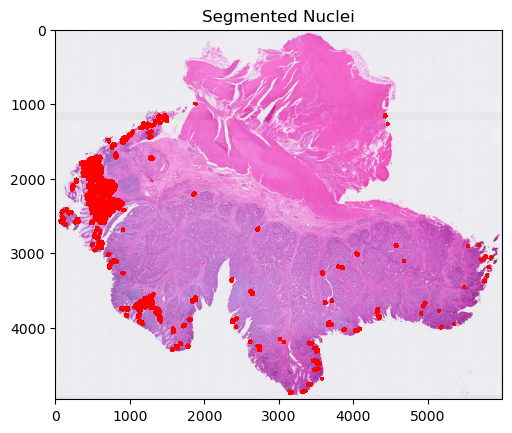

In [4]:
## Test 1

labels_test1 = stardist_2D_versatile_he(img, 0.5, None)

# Plot
plt.imshow(img, cmap='gray')
plt.contour(labels_test1, levels=np.unique(labels_test1)[1:], colors='red')
plt.title("Segmented Nuclei")
plt.show()

In [5]:
sq.im.segment(
    img=img_container,
    layer="image",
    channel=None,
    method=stardist_2D_versatile_he,
    layer_added="segmented_stardist_default",
    prob_thresh=None,
    nms_thresh=None,
)

Found model '2D_versatile_he' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.692478, nms_thresh=0.3.


_container.py (1371): The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


ImageContainer[shape=(4961, 6000), layers=['image', 'segmented_stardist_default']]
Number of segments in crop: 344


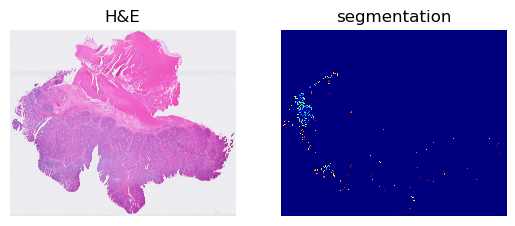

In [6]:
print(img_container)
print(
    f"Number of segments in crop: {len(np.unique(img_container['segmented_stardist_default']))}"
)

fig, axes = plt.subplots(1, 2)
img_container.show("image", ax=axes[0])
_ = axes[0].set_title("H&E")
img_container.show("segmented_stardist_default", cmap="jet", interpolation="none", ax=axes[1])
_ = axes[1].set_title("segmentation")